# 04 · La concurrence fait-elle baisser les prix ?

Le notebook 01 trouvait, sur la photo du 19 octobre 2026, à peine 2 centimes d'écart entre les stations isolées et celles qui ont six à dix concurrents autour d'elles. Mais ce jour-là, en pleine crise, presque toutes les stations TotalEnergies affichaient le même prix de 2,25 €, et la comparaison ne tenait compte ni de l'enseigne ni de la région. Ce notebook reprend la question sur une année normale, puis l'aborde par une expérience naturelle : l'ouverture d'une station de grande surface.

**Questions**
1. Combien l'enseigne pèse-t-elle dans le prix d'une station ?
2. À enseigne et département égaux, une station entourée de concurrents, ou proche d'une grande surface, est-elle moins chère ?
3. Quand une grande surface ouvre une station, les stations voisines baissent-elles leurs prix ?

On travaille sur le **gazole**, le carburant le plus vendu, et sur l'**écart de chaque station au prix médian national de la semaine**, en centimes : cela retire les variations du pétrole et des taxes, communes à toutes les stations. Les enseignes viennent d'OpenStreetMap (relevé d'octobre 2026). Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.formula.api as smf

from carburants import analyse, concurrence, enseignes

DONNEES = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
chiffres = {}

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def vers_pandas(table, colonnes):
    # statsmodels attend un DataFrame pandas ; on évite la dépendance à pyarrow
    return pd.DataFrame({colonne: table[colonne].to_list() for colonne in colonnes})

## Les données

Trois ingrédients :
- la série hebdomadaire du gazole de chaque station depuis 2007 (même reconstruction que le notebook 02) ;
- la position et le code postal de chaque station, tirés des fichiers annuels ;
- l'enseigne, appariée à OpenStreetMap à moins de 250 mètres. Les stations **Total Access**, format à bas prix de TotalEnergies, sont repérées par leur nom et séparées des autres stations du groupe. En 2025, 23 % des stations n'ont pas d'enseigne connue.

Les stations d'outre-mer, dont les prix maximaux sont fixés par les préfets, et celles de Corse, marché insulaire à part, sont écartées.

In [2]:
HISTORIQUE = DONNEES / "historique"
prix = analyse.charger_historique(HISTORIQUE)
hebdo = analyse.prix_hebdo(prix.filter(pl.col("carburant") == "Gazole"))
# Écart au prix médian national de la semaine, en centimes
hebdo = hebdo.with_columns(ecart=(pl.col("prix") - pl.col("prix").median().over("semaine")) * 100)

fichier_enseignes = sorted((DONNEES / "enseignes").glob("stations_enseignes_*.parquet"))[-1]
print("Enseignes :", fichier_enseignes.name)
# On renormalise les enseignes avec la version actuelle des règles (« Station U » est une station Système U)
appariement = pl.read_parquet(fichier_enseignes).with_columns(
    enseigne=pl.when(pl.col("enseigne").is_not_null()).then(
        pl.struct("osm_marque", "osm_nom").map_elements(
            lambda r: enseignes.normaliser(r["osm_marque"], r["osm_nom"]), return_dtype=pl.Utf8
        )
    )
).with_columns(
    grande_surface=pl.col("enseigne").is_in(list(enseignes.GRANDES_SURFACES)).fill_null(False),
    total_access=(pl.col("enseigne") == "TotalEnergies") & enseignes.total_access(pl.col("osm_marque"), pl.col("osm_nom")),
)

stations = (
    analyse.stations_connues(HISTORIQUE).rename({"id": "station_id"})
    .filter(pl.col("latitude").is_between(42.3, 51.5), pl.col("longitude").is_between(-5.5, 8.3), pl.col("departement") != "20")
    .join(appariement.select("station_id", "enseigne", "grande_surface", "total_access"), on="station_id", how="left")
    .with_columns(pl.col("grande_surface", "total_access").fill_null(False))
)
vies = (
    hebdo.group_by("station_id").agg(debut=pl.col("semaine").min(), fin=pl.col("semaine").max())
    .join(stations, on="station_id", how="inner")
)
print(f"{hebdo.height:,} prix hebdomadaires, {vies.height:,} stations de métropole continentale")

Enseignes : stations_enseignes_2026-10-19.parquet


8,887,345 prix hebdomadaires, 14,177 stations de métropole continentale


## 1. L'enseigne avant tout

On décrit chaque station par son écart moyen au prix médian national en **2025**, dernière année complète avant la crise, en ne gardant que les stations qui publient au moins six mois. On les classe en sept groupes : les stations d'autoroute, les grandes surfaces (E.Leclerc, Intermarché, Carrefour, Système U, Auchan, Casino, Netto, Cora), TotalEnergies Access, les autres stations TotalEnergies, les autres pétroliers (Esso, BP, Shell, Avia, Eni, Dyneff), les autres enseignes, et les stations sans enseigne connue.

In [3]:
PETROLIERS = ["Esso", "BP", "Shell", "Avia", "Eni", "Dyneff"]
GROUPES = ["Grande surface", "TotalEnergies Access", "Sans enseigne connue", "Autre enseigne", "Autre pétrolier", "TotalEnergies", "Autoroute"]

def groupe():
    return (
        pl.when(pl.col("type_route") == "autoroute").then(pl.lit("Autoroute"))
        .when(pl.col("grande_surface")).then(pl.lit("Grande surface"))
        .when(pl.col("total_access")).then(pl.lit("TotalEnergies Access"))
        .when(pl.col("enseigne") == "TotalEnergies").then(pl.lit("TotalEnergies"))
        .when(pl.col("enseigne").is_in(PETROLIERS)).then(pl.lit("Autre pétrolier"))
        .when(pl.col("enseigne").is_null()).then(pl.lit("Sans enseigne connue"))
        .otherwise(pl.lit("Autre enseigne"))
    )

def coupe(annee):
    """Les stations de l'année, leur écart moyen et leur environnement concurrentiel."""
    actives = (
        hebdo.filter(pl.col("semaine").dt.year() == annee)
        .group_by("station_id").agg(ecart=pl.col("ecart").mean(), semaines=pl.len())
        .join(stations, on="station_id", how="inner")
    )
    # Les concurrents sont toutes les stations qui publient dans l'année, même peu de semaines
    actives = concurrence.voisins(actives, [1, 5, 10])
    actives = actives.with_columns(
        gms_km=concurrence.distance_plus_proche(actives, actives.filter(pl.col("grande_surface"))),
        groupe=groupe(),
    )
    return actives.filter(pl.col("semaines") >= 26)

stations_2025 = coupe(2025)
resume = (
    stations_2025.group_by("groupe")
    .agg(stations=pl.len(), ecart_moyen=pl.col("ecart").mean(), p10=pl.col("ecart").quantile(0.1), p90=pl.col("ecart").quantile(0.9))
    .sort(pl.col("groupe").replace_strict(GROUPES, list(range(len(GROUPES)))))
)
chiffres["stations_2025"] = stations_2025.height
for nom, cle in [("Grande surface", "gms"), ("TotalEnergies Access", "access"), ("TotalEnergies", "total"), ("Autre pétrolier", "petroliers"), ("Autoroute", "autoroute")]:
    chiffres[f"brut_{cle}"] = resume.filter(groupe=nom)["ecart_moyen"].item()
    chiffres[f"part_{cle}"] = resume.filter(groupe=nom)["stations"].item() / stations_2025.height * 100
chiffres["ecart_brut"] = chiffres["brut_petroliers"] - chiffres["brut_gms"]
chiffres["ecart_brut_plein"] = chiffres["ecart_brut"] / 100 * 50
chiffres["sans_enseigne_2025"] = stations_2025["enseigne"].is_null().mean() * 100
chiffres["access_stations"] = resume.filter(groupe="TotalEnergies Access")["stations"].item()
resume.with_columns(pl.col("ecart_moyen", "p10", "p90").round(1))

groupe,stations,ecart_moyen,p10,p90
str,u32,f64,f64,f64
"""Grande surface""",3899,-1.8,-4.9,1.4
"""TotalEnergies Access""",453,0.3,-3.2,6.3
"""Sans enseigne connue""",2043,1.6,-3.7,9.6
"""Autre enseigne""",116,2.3,-2.2,7.1
"""Autre pétrolier""",1050,6.3,-1.2,14.2
"""TotalEnergies""",1285,8.4,-0.8,14.8
"""Autoroute""",427,18.8,6.0,33.2


En 2025, sur 9 273 stations, les grandes surfaces (42 % des stations) vendent le gazole en moyenne 1,8 centime **sous** la médiane nationale, les stations TotalEnergies classiques 8,4 centimes au-dessus et les autres pétroliers 6,3 centimes au-dessus. Les 453 stations Total Access, elles, sont à +0,3 centime, bien plus près des grandes surfaces que des autres TotalEnergies : sous un même logo, deux politiques de prix. Sur autoroute, l'écart atteint 19 centimes. Entre une grande surface et une station de pétrolier, il y a donc 8 centimes par litre, soit 4 € sur un plein de 50 litres.

## 2. À enseigne égale, la concurrence compte-t-elle ?

Les stations isolées sont souvent rurales, et les campagnes n'ont pas les mêmes coûts que les villes. On estime donc une régression de l'écart de prix sur :
- le **groupe d'enseigne** (référence : grande surface) ;
- le **nombre de concurrents à moins de 5 km**, sous la forme du logarithme de (1 + ce nombre) : passer de 0 à 1 concurrent compte autant que de 1 à 3, ou de 3 à 7 ;
- la **distance à la grande surface la plus proche** (moins de 1 km, 1 à 3, 3 à 5, 5 à 10 km ; référence : plus de 10 km) ;
- le **département** (effets fixes), qui absorbe les différences régionales de coûts et de niveau de prix.

Les stations d'autoroute, sur un marché à part, sont exclues. Les erreurs types sont regroupées par département.

Pour une grande surface, la « grande surface la plus proche » est une autre grande surface, ce qui ne mesure pas la même chose. On estime donc aussi le modèle **sur les seules stations qui ne sont pas des grandes surfaces** : c'est sur elles que se lit le mieux l'effet d'un hypermarché voisin. On vérifie enfin que les résultats tiennent en comptant les concurrents dans un rayon de 1 ou de 10 km plutôt que 5, et sur 2019 plutôt que 2025.

In [4]:
TRANCHES = ["< 1 km", "1-3 km", "3-5 km", "5-10 km", "> 10 km"]

def tranche_gms():
    km = pl.col("gms_km")
    return (pl.when(km < 1).then(pl.lit(TRANCHES[0])).when(km < 3).then(pl.lit(TRANCHES[1]))
            .when(km < 5).then(pl.lit(TRANCHES[2])).when(km < 10).then(pl.lit(TRANCHES[3])).otherwise(pl.lit(TRANCHES[4])))

CONCURRENTS = "log(1 + concurrents)"

def regression(table, rayon=5, sans_gms=False):
    """Régression de l'écart de prix ; renvoie le modèle, ses coefficients et l'échantillon."""
    echantillon = table.filter(pl.col("groupe") != "Autoroute")
    reference = "Grande surface"
    if sans_gms:
        echantillon, reference = echantillon.filter(~pl.col("grande_surface")), "Sans enseigne connue"
    donnees = vers_pandas(echantillon.with_columns(tranche=tranche_gms(), concurrents=pl.col(f"voisins_{rayon}km")),
                          ["ecart", "groupe", "concurrents", "tranche", "departement"])
    formule = (f"ecart ~ C(groupe, Treatment('{reference}')) + np.log1p(concurrents) "
               "+ C(tranche, Treatment('> 10 km')) + C(departement)")
    modele = smf.ols(formule, data=donnees).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(donnees["departement"])[0]})
    lignes = [nom for nom in modele.params.index if not nom.startswith("C(departement)") and nom != "Intercept"]
    libelles = {nom: nom.split("[T.")[-1].rstrip("]") if "[T." in nom else CONCURRENTS for nom in lignes}
    coefs = pl.DataFrame({
        "variable": [libelles[n] for n in lignes],
        "coef": modele.params[lignes].to_numpy(),
        "erreur": modele.bse[lignes].to_numpy(),
    })
    return modele, coefs, echantillon

tables = {2025: stations_2025, 2019: coupe(2019)}
modeles = {}
for annee, table in tables.items():
    for sans_gms in [False, True]:
        for rayon in [1, 5, 10]:
            modeles[annee, sans_gms, rayon] = regression(table, rayon, sans_gms)

# L'effet du nombre de concurrents sur la plage observée : du premier quartile (p25) au dernier décile (p90)
q25, q90 = np.percentile(modeles[2025, False, 5][2]["voisins_5km"].to_numpy(), [25, 90])
chiffres["voisins_p25"], chiffres["voisins_p90"] = q25, q90
facteur_plage = np.log((1 + q90) / (1 + q25))
for (annee, sans_gms, rayon), (modele, coefs, _) in modeles.items():
    coef = dict(zip(coefs["variable"], coefs["coef"]))
    erreur = dict(zip(coefs["variable"], coefs["erreur"]))
    suffixe = f"{'_hors_gms' if sans_gms else ''}{'' if rayon == 5 else f'_{rayon}km'}_{annee}"
    for tranche, cle in [("< 1 km", "gms1"), ("1-3 km", "gms3"), ("3-5 km", "gms5"), ("5-10 km", "gms10")]:
        chiffres[f"reg_{cle}{suffixe}"] = coef[tranche]
        chiffres[f"reg_{cle}_erreur{suffixe}"] = erreur[tranche]
    if rayon != 5:
        continue
    chiffres[f"n_reg{suffixe}"] = modele.nobs
    chiffres[f"reg_plage{suffixe}"] = coef[CONCURRENTS] * facteur_plage
    chiffres[f"reg_plage_erreur{suffixe}"] = erreur[CONCURRENTS] * facteur_plage
    chiffres[f"reg_zero_dix{suffixe}"] = coef[CONCURRENTS] * np.log(11)
    if not sans_gms:
        chiffres[f"r2_{annee}"] = modele.rsquared
        chiffres[f"reg_total_{annee}"] = coef["TotalEnergies"]
        chiffres[f"reg_access_{annee}"] = coef["TotalEnergies Access"]
        chiffres[f"reg_access_erreur_{annee}"] = erreur["TotalEnergies Access"]
        chiffres[f"reg_petroliers_{annee}"] = coef["Autre pétrolier"]
chiffres["plage_sur_enseigne"] = -chiffres["reg_plage_hors_gms_2025"] / chiffres["reg_total_2025"] * 100
print(f"Concurrents à moins de 5 km : p25 = {q25:.0f}, p90 = {q90:.0f}")
pl.DataFrame([
    {"année": annee, "échantillon": "hors grandes surfaces" if sans_gms else "toutes", "rayon (km)": rayon,
     **{v: round(c, 2) for v, c in zip(coefs["variable"], coefs["coef"]) if v in (CONCURRENTS, "< 1 km", "1-3 km", "3-5 km")}}
    for (annee, sans_gms, rayon), (_, coefs, _) in modeles.items()
])

Concurrents à moins de 5 km : p25 = 1, p90 = 17


année,échantillon,rayon (km),1-3 km,3-5 km,< 1 km,log(1 + concurrents)
i64,str,i64,f64,f64,f64,f64
2025,"""toutes""",1,-1.28,-0.73,-0.81,-0.63
2025,"""toutes""",5,-0.55,-0.15,-0.55,-0.54
2025,"""toutes""",10,-0.79,-0.24,-0.78,-0.32
2025,"""hors grandes surfaces""",1,-1.28,-0.59,-0.5,-1.12
2025,"""hors grandes surfaces""",5,-0.25,0.22,-0.27,-0.76
2025,"""hors grandes surfaces""",10,-0.54,0.14,-0.55,-0.49
2019,"""toutes""",1,-1.23,-0.74,-0.56,-0.46
2019,"""toutes""",5,-0.6,-0.22,-0.31,-0.47
2019,"""toutes""",10,-0.77,-0.28,-0.46,-0.31


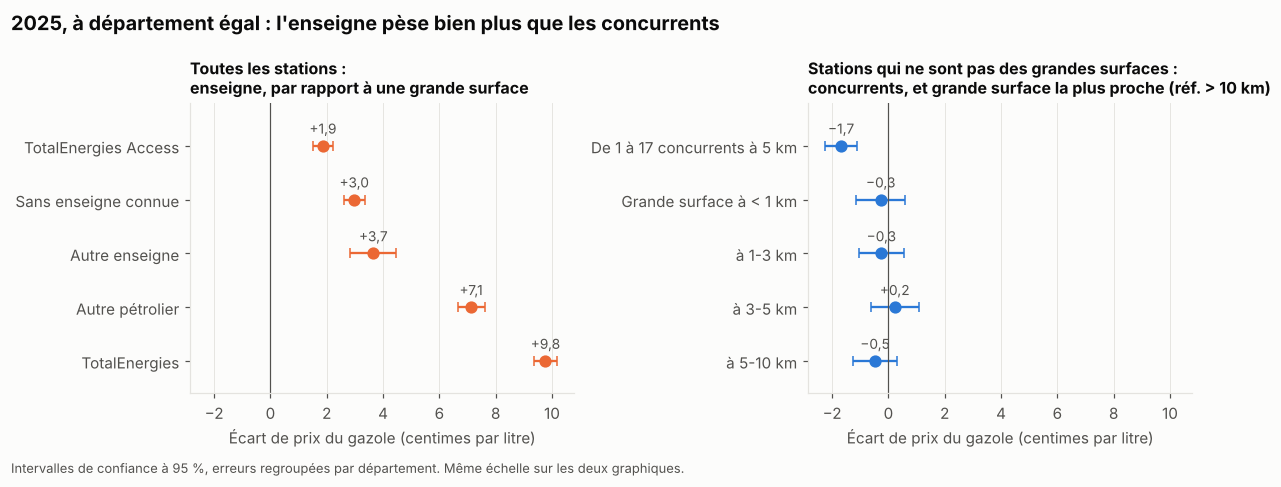

In [5]:
_, coefs_enseignes, _ = modeles[2025, False, 5]
_, coefs_concurrence, _ = modeles[2025, True, 5]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
plage = pl.DataFrame({
    "variable": [f"De {q25:.0f} à {q90:.0f} concurrents à 5 km"],
    "coef": [chiffres["reg_plage_hors_gms_2025"]], "erreur": [chiffres["reg_plage_erreur_hors_gms_2025"]],
})
blocs = [
    (axes[0], coefs_enseignes, ["TotalEnergies Access", "Sans enseigne connue", "Autre enseigne", "Autre pétrolier", "TotalEnergies"],
     "Toutes les stations :\nenseigne, par rapport à une grande surface", ORANGE),
    (axes[1], pl.concat([plage, coefs_concurrence]), [plage["variable"][0], *TRANCHES[:-1]],
     "Stations qui ne sont pas des grandes surfaces :\nconcurrents, et grande surface la plus proche (réf. > 10 km)", BLEU),
]
for ax, coefs, variables, titre, couleur in blocs:
    sous = coefs.filter(pl.col("variable").is_in(variables)).sort(pl.col("variable").replace_strict(variables, list(range(len(variables)))))
    y = np.arange(sous.height)[::-1]
    ax.errorbar(sous["coef"], y, xerr=1.96 * sous["erreur"], fmt="o", color=couleur, ecolor=couleur, elinewidth=1.5, capsize=3, markersize=7)
    for yi, valeur in zip(y, sous["coef"]):
        ax.annotate(f"{valeur:+.1f}".replace(".", ",").replace("-", "−"), (valeur, yi), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=9, color=TEXTE_2)
    ax.set_yticks(y, [v.replace("< 1 km", "Grande surface à < 1 km").replace("1-3 km", "à 1-3 km").replace("3-5 km", "à 3-5 km")
                      .replace("5-10 km", "à 5-10 km") for v in sous["variable"]])
    ax.set_ylim(-0.6, sous.height - 0.2)  # de la place pour les étiquettes du haut
    ax.xaxis.set_major_formatter(lambda valeur, _: f"{valeur:g}".replace(".", ",").replace("-", "−"))
    ax.axvline(0, color=TEXTE_2, linewidth=0.8)
    ax.set_title(titre, fontsize=10.5)
    ax.set_xlabel("Écart de prix du gazole (centimes par litre)")
    ax.grid(axis="y", visible=False)
fig.suptitle("2025, à département égal : l'enseigne pèse bien plus que les concurrents",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.text(0.01, -0.02, "Intervalles de confiance à 95 %, erreurs regroupées par département. Même échelle sur les deux graphiques.",
         fontsize=8.5, color=TEXTE_2)
fig.tight_layout()
sauver(fig, "15_enseigne_et_concurrence")

À département et environnement égaux, une station TotalEnergies classique vend le gazole 9,8 centimes plus cher qu'une grande surface, et un autre pétrolier 7,1 centimes plus cher (respectivement 8,2 et 5,7 en 2019). Une station Total Access, elle, n'est que 1,9 centimes plus chère qu'une grande surface (± 0,4). L'enseigne reste de loin le premier facteur.

La concurrence joue, mais moins :
- **le nombre de concurrents** : entre une station qui en a 1 à moins de 5 km (le quart le moins entouré) et une qui en a 17 (les 10 % les plus entourés), le prix baisse de 1,2 centimes (± 0,4). L'effet est plus net pour les stations qui ne sont pas des grandes surfaces : 1,7 centimes (± 0,6), environ 17 % de l'écart entre une station TotalEnergies et une grande surface ;
- **une grande surface toute proche** : pour une station qui n'en est pas une, en avoir une à moins de 1 km ne se distingue pas de zéro (−0,3 centime, ± 0,9), pas plus qu'à 1-3 km (−0,3, ± 0,8).

Ces écarts dépendent toutefois de la façon de compter. Sur toutes les stations, une grande surface à 1-3 km est associée à −0,5 centime en 2025 (± 0,4) et −0,6 en 2019 (± 0,4), deux écarts cette fois différents de zéro, car les grandes surfaces y comptent aussi ; et si l'on compte les concurrents à moins de 1 km plutôt que 5, cet écart passe à −1,3 centime en 2025 : les deux variables se partagent le même effet de proximité. Le nombre de concurrents garde le même ordre de grandeur en 2019 (de 1 à 17 concurrents : −1,0 centime).

Ces écarts restent des corrélations : une grande surface s'installe là où il y a des clients, et les stations voisines peuvent différer par d'autres traits que le modèle ne voit pas.

## 3. Une expérience naturelle : l'ouverture d'une station de grande surface

Pour se rapprocher d'un effet causal, on regarde ce qui se passe **autour d'une ouverture**. Une station est considérée comme ouverte la première semaine où elle publie un prix, à partir de 2009. On écarte les « ouvertures » qui ne sont que des changements d'identifiant : une station qui apparaît à moins de 300 mètres d'une station disparue à quatre mois près.

On compare ensuite, autour de chaque ouverture, les stations déjà présentes **à moins de 3 km** (traitées) et celles situées **entre 10 et 20 km** (témoins), présentes six mois avant et un an après. L'écart entre les deux groupes, recentré sur sa moyenne **de six mois à un mois avant l'ouverture** (la référence), mesure l'effet de l'arrivée du nouveau concurrent (différence de différences). Chaque ouverture compte pour une observation ; les erreurs types sont regroupées par département, car des ouvertures voisines partagent des stations témoins.

Une limite importante : une station qui « apparaît » dans les données n'est pas toujours une station neuve. Certaines existaient sans publier leurs prix, d'autres reprennent une station fermée un peu plus loin ou plus longtemps avant que la règle ne le prévoit. Pour elles, il n'y a aucun choc de concurrence, ce qui tire l'effet mesuré vers zéro. On teste plus bas une règle plus stricte.

In [6]:
FENETRES = {"anticipation": (-4, -1), "court": (0, 12), "long": (13, 52)}
departement_station = dict(zip(vies["station_id"], vies["departement"]))

def etude(evenements, paires=None):
    """Différences de différences autour des ouvertures : profil semaine par semaine et effets par fenêtre."""
    paires = concurrence.paires_evenement(vies, evenements) if paires is None else paires
    differences = concurrence.differences_evenement(hebdo, paires)
    grappes = pl.DataFrame({"evenement": evenements["station_id"]}).with_columns(
        grappe=pl.col("evenement").replace_strict(departement_station, default=None)
    )
    effets = {nom: concurrence.effet_moyen(differences, debut, fin, grappes) for nom, (debut, fin) in FENETRES.items()}
    return {"paires": paires, "differences": differences, "profil": concurrence.profil_evenement(differences), "effets": effets}

ouvertures = concurrence.ouvertures(vies, depuis=date(2009, 1, 1)).filter(pl.col("debut") <= date(2025, 9, 1))
gms_ouvertures = ouvertures.filter(pl.col("grande_surface"))
chiffres["ouvertures"] = ouvertures.height
chiffres["ouvertures_gms"] = gms_ouvertures.height
resultats = {"gms": etude(gms_ouvertures), "autres": etude(ouvertures.filter(~pl.col("grande_surface")))}
for nom, resultat in resultats.items():
    for fenetre, effet in resultat["effets"].items():
        chiffres[f"evt_{nom}_{fenetre}"] = effet["effet"]
        chiffres[f"evt_{nom}_{fenetre}_erreur"] = effet["erreur"]
    chiffres[f"evt_{nom}_ouvertures"] = resultat["differences"]["evenement"].n_unique()
    chiffres[f"evt_{nom}_traitees"] = resultat["paires"].filter(groupe="traitee").height
    print(f"{nom} : {chiffres[f'evt_{nom}_ouvertures']:.0f} ouvertures utilisables, {chiffres[f'evt_{nom}_traitees']:.0f} paires traitées")

# Tendance avant la référence : pente de la différence sur les semaines -26 à -5, ouverture par ouverture
pentes = (
    resultats["gms"]["differences"].filter(pl.col("k") <= -5)
    .group_by("evenement").agg(pente=pl.cov("k", "difference") / pl.col("k").var())
)["pente"].drop_nulls()
chiffres["pre_pente"] = pentes.mean()
chiffres["pre_pente_erreur"] = pentes.std() / np.sqrt(pentes.len())
pl.DataFrame([{"ouvertures": nom, "fenêtre": fenetre, "effet (c)": round(chiffres[f"evt_{nom}_{fenetre}"], 2),
               "erreur (c)": round(chiffres[f"evt_{nom}_{fenetre}_erreur"], 2)}
              for nom in resultats for fenetre in FENETRES])

gms : 743 ouvertures utilisables, 2194 paires traitées
autres : 2503 ouvertures utilisables, 10544 paires traitées


ouvertures,fenêtre,effet (c),erreur (c)
str,str,f64,f64
"""gms""","""anticipation""",-0.13,0.06
"""gms""","""court""",-0.34,0.06
"""gms""","""long""",-0.26,0.05
"""autres""","""anticipation""",-0.05,0.03
"""autres""","""court""",-0.05,0.03
"""autres""","""long""",-0.08,0.03


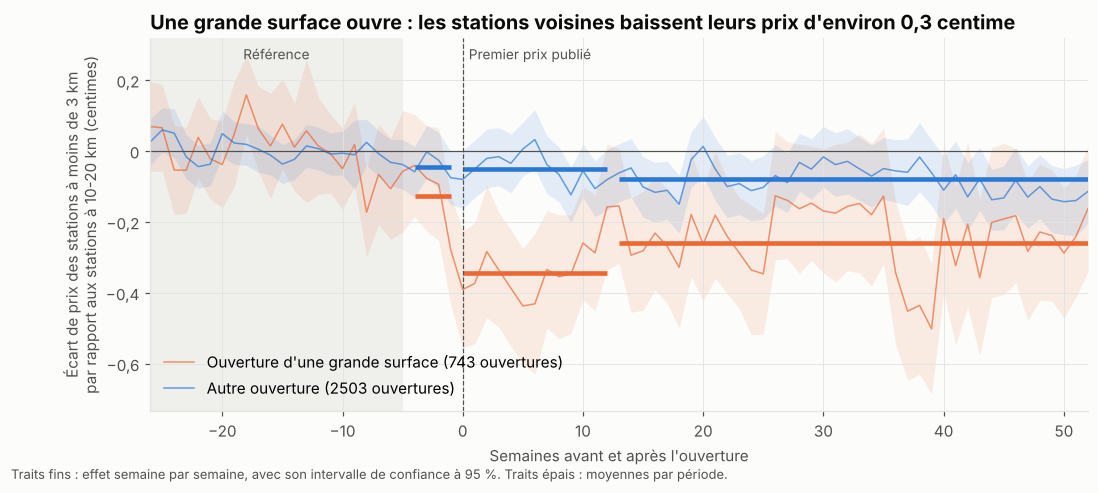

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.axvspan(-26, -5, color=GRILLE, alpha=0.5, linewidth=0)
ax.annotate("Référence", (-15.5, 0.98), xycoords=("data", "axes fraction"), ha="center", va="top", fontsize=9, color=TEXTE_2)
for nom, couleur, libelle in [("gms", ORANGE, "Ouverture d'une grande surface"), ("autres", BLEU, "Autre ouverture")]:
    profil = resultats[nom]["profil"]
    ax.fill_between(profil["k"], profil["effet"] - 1.96 * profil["erreur"], profil["effet"] + 1.96 * profil["erreur"],
                    color=couleur, alpha=0.12, linewidth=0)
    ax.plot(profil["k"], profil["effet"], color=couleur, linewidth=1, alpha=0.7,
            label=f"{libelle} ({chiffres[f'evt_{nom}_ouvertures']:.0f} ouvertures)")
    # Moyennes par fenêtre, en trait épais
    for fenetre, (debut, fin) in FENETRES.items():
        ax.hlines(chiffres[f"evt_{nom}_{fenetre}"], debut, fin, color=couleur, linewidth=3)
ax.axvline(0, color=TEXTE_2, linewidth=0.8, linestyle="--")
ax.annotate("Premier prix publié", (0.5, 0.98), xycoords=("data", "axes fraction"), va="top", fontsize=9, color=TEXTE_2)
ax.axhline(0, color=TEXTE_2, linewidth=0.8)
ax.set_xlabel("Semaines avant et après l'ouverture")
ax.set_ylabel("Écart de prix des stations à moins de 3 km\npar rapport aux stations à 10-20 km (centimes)")
ax.yaxis.set_major_formatter(lambda valeur, _: f"{valeur:g}".replace(".", ",").replace("-", "−"))
ax.set_xlim(-26, 52)
ax.set_title("Une grande surface ouvre : les stations voisines baissent leurs prix d'environ 0,3 centime")
ax.legend(loc="lower left", frameon=False)
fig.text(0.01, -0.03, "Traits fins : effet semaine par semaine, avec son intervalle de confiance à 95 %. Traits épais : moyennes par période.",
         fontsize=8.5, color=TEXTE_2)
sauver(fig, "16_ouvertures")

### Ce résultat est-il solide ?

Quatre vérifications sur les ouvertures de grandes surfaces :
- **un placebo** : la même analyse avec une fausse date d'ouverture, un an avant la vraie. Il ne devrait rien se passer ;
- **la distance** : si l'effet vient bien du nouveau concurrent, il doit être plus fort pour les stations les plus proches ;
- **une règle plus stricte contre les reprises** : on écarte toute station apparue à moins de 1 km d'une station disparue dans l'année ;
- **sans 2024** : cette année compte deux fois plus d'« ouvertures » de grandes surfaces que les autres, surtout entre mai et juillet, au moment où les magasins Casino ont été repris par Intermarché, Carrefour et Auchan.

In [8]:
robustesse = {}
placebo = gms_ouvertures.with_columns(pl.col("debut") - pl.duration(weeks=52))
robustesse["placebo"] = etude(placebo)
paires_gms = resultats["gms"]["paires"]
temoins = paires_gms.filter(groupe="temoin")
robustesse["moins_1km"] = etude(gms_ouvertures, pl.concat([paires_gms.filter((pl.col("groupe") == "traitee") & (pl.col("distance_km") <= 1)), temoins]))
robustesse["1_3km"] = etude(gms_ouvertures, pl.concat([paires_gms.filter((pl.col("groupe") == "traitee") & (pl.col("distance_km") > 1)), temoins]))
strictes = concurrence.ouvertures(vies, depuis=date(2009, 1, 1), rayon_remplacement_m=1000, jours_remplacement=365)
strictes = strictes.filter(pl.col("grande_surface"), pl.col("debut") <= date(2025, 9, 1))
robustesse["stricte"] = etude(strictes)
robustesse["sans_2024"] = etude(gms_ouvertures.filter(pl.col("debut").dt.year() != 2024))
chiffres["ouvertures_gms_2024"] = gms_ouvertures.filter(pl.col("debut").dt.year() == 2024).height
sans_enseigne_2019 = tables[2019].filter(pl.col("enseigne").is_null())
chiffres["sans_enseigne_2019"] = sans_enseigne_2019.height / tables[2019].height * 100
releve_2026 = set(appariement["station_id"].to_list())
chiffres["sans_enseigne_2019_fermees"] = (~sans_enseigne_2019["station_id"].is_in(releve_2026)).mean() * 100
autres_ouvertures = ouvertures.filter(~pl.col("grande_surface"))
chiffres["autres_ouvertures_absentes"] = (~autres_ouvertures["station_id"].is_in(releve_2026)).mean() * 100
chiffres["ouvertures_gms_par_an"] = gms_ouvertures.filter(pl.col("debut").dt.year().is_between(2010, 2023)).height / 14
lignes = []
for nom, resultat in robustesse.items():
    for fenetre, effet in resultat["effets"].items():
        chiffres[f"rob_{nom}_{fenetre}"] = effet["effet"]
        chiffres[f"rob_{nom}_{fenetre}_erreur"] = effet["erreur"]
    chiffres[f"rob_{nom}_ouvertures"] = resultat["differences"]["evenement"].n_unique()
    lignes.append({"variante": nom, "ouvertures": chiffres[f"rob_{nom}_ouvertures"],
                   **{f"{f} (c)": round(e["effet"], 2) for f, e in resultat["effets"].items()},
                   **{f"{f} erreur": round(e["erreur"], 2) for f, e in resultat["effets"].items()}})
pl.DataFrame(lignes)

variante,ouvertures,anticipation (c),court (c),long (c),anticipation erreur,court erreur,long erreur
str,i64,f64,f64,f64,f64,f64,f64
"""placebo""",751,-0.16,-0.03,0.01,0.07,0.06,0.06
"""moins_1km""",358,-0.21,-0.45,-0.47,0.11,0.1,0.1
"""1_3km""",619,-0.16,-0.27,-0.19,0.06,0.07,0.07
"""stricte""",517,-0.23,-0.4,-0.31,0.07,0.07,0.08
"""sans_2024""",643,-0.15,-0.36,-0.27,0.06,0.06,0.06


Sur 1 157 ouvertures de stations de grande surface depuis 2009, 743 ont à la fois des stations voisines et des stations témoins présentes sur toute la période. Après l'ouverture, les stations voisines baissent leurs prix par rapport aux témoins : **−0,34 centime** en moyenne pendant les trois premiers mois (± 0,11), et encore −0,26 centime (± 0,11) du quatrième au douzième mois. Avant la référence, les deux groupes n'ont pas de tendance divergente (pente de −0,004 centime par semaine, ± 0,009).

Les vérifications confortent ce résultat :
- **le placebo ne donne rien après la fausse date** (−0,03 centime sur trois mois, +0,01 ensuite). Il reproduit en revanche le léger creux des quatre semaines qui précèdent (−0,16 centime, contre −0,13 avec les vraies dates) : ce creux n'est donc pas une anticipation de l'ouverture, mais un effet de la méthode ou du hasard ;
- **l'effet décroît avec la distance** : −0,47 centime (± 0,20) pour les stations à moins de 1 km, −0,19 (± 0,13) entre 1 et 3 km, du quatrième au douzième mois ;
- **avec la règle stricte contre les reprises**, il reste 517 ouvertures et l'effet est du même ordre (−0,31 centime, ± 0,16) ;
- **sans 2024** (137 ouvertures cette année-là, contre 62 par an en moyenne de 2010 à 2023), l'effet est de −0,27 centime.

L'ouverture d'une autre station a un effet plus faible (−0,08 centime du quatrième au douzième mois, ± 0,05).

L'effet est réel mais petit : quelques millièmes d'euro par litre en moyenne, un demi-centime pour les stations les plus proches. Les deux approches concordent : l'arrivée d'un concurrent, même une grande surface, ne bouscule pas les prix des stations voisines.

## Limites

- **Enseignes d'aujourd'hui** : l'enseigne vient d'OpenStreetMap en 2026 et s'applique aux années passées. Une station qui a changé d'enseigne est mal classée avant le changement, et une station fermée depuis n'a pas d'enseigne du tout : en 2019, 34 % des stations n'ont pas d'enseigne connue, dont 50 % ont fermé depuis. De même, 45 % des « autres ouvertures » sont des stations absentes du relevé de 2026 : certaines étaient peut-être des grandes surfaces.
- **Groupes d'enseignes** : les « autres enseignes » mêlent de petites enseignes de supermarché (Match, Spar, Aldi…) et des marques indépendantes.
- **Concurrents qui publient** : seules les stations qui déclarent leurs prix comptent comme concurrentes ; les plus petites, dispensées, sont invisibles.
- **Distance à vol d'oiseau** : 3 km à vol d'oiseau peuvent faire 10 minutes de route, ou être de l'autre côté d'une autoroute.
- **Stations présentes toute la fenêtre** : l'étude ne garde que les stations encore ouvertes un an après l'ouverture ; si l'arrivée d'une grande surface en faisait fermer, cet effet serait invisible ici.
- **Gazole seulement** ; l'essence pourrait réagir différemment.

## À retenir

- **L'enseigne fait le prix** : en 2025, à département égal, une station TotalEnergies classique vend le gazole 10 centimes plus cher qu'une grande surface, les autres pétroliers 7 centimes plus cher ; les stations Total Access ne sont que 2 centimes plus chères qu'une grande surface.
- **La concurrence locale compte moins** : entre une station peu entourée et une station très entourée, l'écart est de 1,2 centimes (1,7 hors grandes surfaces), et une grande surface toute proche n'y ajoute rien de mesurable.
- **L'ouverture d'une grande surface** fait baisser les prix des stations voisines d'environ 0,3 centime, un peu plus à moins de 1 km ; un placebo confirme que ce n'est pas un artefact.
- Pour l'automobiliste, le choix de la station (et surtout de l'enseigne) compte bien plus que le nombre de stations du quartier.
- Prochaine étape : un modèle qui prédit le prix d'une station à partir de toutes ces caractéristiques, et qui dit lesquelles comptent le plus.

In [9]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_04.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1) + "\n")
CITES = {
 "sans_enseigne_2025": [
  22.991481,
  0.5
 ],
 "stations_2025": [
  9273.0,
  0.5
 ],
 "part_gms": [
  42.046803,
  0.5
 ],
 "brut_gms": [
  -1.805107,
  0.05
 ],
 "brut_total": [
  8.384982,
  0.05
 ],
 "brut_petroliers": [
  6.251501,
  0.05
 ],
 "access_stations": [
  453.0,
  0.5
 ],
 "brut_access": [
  0.327804,
  0.05
 ],
 "brut_autoroute": [
  18.839543,
  0.5
 ],
 "ecart_brut": [
  8.056608,
  0.5
 ],
 "ecart_brut_plein": [
  4.028304,
  0.5
 ],
 "reg_total_2025": [
  9.768235,
  0.5
 ],
 "reg_petroliers_2025": [
  7.126925,
  0.5
 ],
 "reg_total_2019": [
  8.209447,
  0.05
 ],
 "reg_petroliers_2019": [
  5.723192,
  0.05
 ],
 "reg_access_2025": [
  1.865465,
  0.5
 ],
 "reg_access_erreur_2025": [
  0.18592,
  0.025510204081632654
 ],
 "voisins_p25": [
  1.0,
  0.5
 ],
 "voisins_p90": [
  17.0,
  0.5
 ],
 "reg_plage_2025": [
  -1.195906,
  0.05
 ],
 "reg_plage_erreur_2025": [
  0.190359,
  0.025510204081632654
 ],
 "reg_plage_hors_gms_2025": [
  -1.680053,
  0.05
 ],
 "reg_plage_erreur_hors_gms_2025": [
  0.28402,
  0.025510204081632654
 ],
 "plage_sur_enseigne": [
  17.19915,
  0.5
 ],
 "reg_gms1_hors_gms_2025": [
  -0.272753,
  0.05
 ],
 "reg_gms1_erreur_hors_gms_2025": [
  0.440819,
  0.025510204081632654
 ],
 "reg_gms3_hors_gms_2025": [
  -0.250027,
  0.05
 ],
 "reg_gms3_erreur_hors_gms_2025": [
  0.406483,
  0.025510204081632654
 ],
 "reg_gms3_2025": [
  -0.548433,
  0.05
 ],
 "reg_gms3_erreur_2025": [
  0.21837,
  0.025510204081632654
 ],
 "reg_gms3_2019": [
  -0.595886,
  0.05
 ],
 "reg_gms3_erreur_2019": [
  0.187851,
  0.025510204081632654
 ],
 "reg_gms3_1km_2025": [
  -1.281081,
  0.05
 ],
 "reg_plage_2019": [
  -1.041016,
  0.05
 ],
 "ouvertures_gms": [
  1157.0,
  0.5
 ],
 "evt_gms_ouvertures": [
  743.0,
  0.5
 ],
 "evt_gms_court": [
  -0.343598,
  0.005
 ],
 "evt_gms_court_erreur": [
  0.057299,
  0.0025510204081632655
 ],
 "evt_gms_long": [
  -0.259854,
  0.05
 ],
 "evt_gms_long_erreur": [
  0.05464,
  0.0025510204081632655
 ],
 "pre_pente": [
  -0.003662,
  0.0005
 ],
 "pre_pente_erreur": [
  0.004434,
  0.00025510204081632655
 ],
 "rob_placebo_court": [
  -0.031818,
  0.005
 ],
 "rob_placebo_long": [
  0.013571,
  0.005
 ],
 "rob_placebo_anticipation": [
  -0.164642,
  0.005
 ],
 "evt_gms_anticipation": [
  -0.128376,
  0.005
 ],
 "rob_moins_1km_long": [
  -0.467558,
  0.005
 ],
 "rob_moins_1km_long_erreur": [
  0.102214,
  0.0025510204081632655
 ],
 "rob_1_3km_long": [
  -0.189277,
  0.005
 ],
 "rob_1_3km_long_erreur": [
  0.065451,
  0.0025510204081632655
 ],
 "rob_stricte_ouvertures": [
  517.0,
  0.5
 ],
 "rob_stricte_long": [
  -0.307072,
  0.005
 ],
 "rob_stricte_long_erreur": [
  0.07912,
  0.0025510204081632655
 ],
 "ouvertures_gms_2024": [
  137.0,
  0.5
 ],
 "ouvertures_gms_par_an": [
  61.714286,
  0.5
 ],
 "rob_sans_2024_long": [
  -0.272834,
  0.005
 ],
 "evt_autres_long": [
  -0.078933,
  0.005
 ],
 "evt_autres_long_erreur": [
  0.027066,
  0.0025510204081632655
 ],
 "sans_enseigne_2019": [
  33.870791,
  0.5
 ],
 "sans_enseigne_2019_fermees": [
  50.259067,
  0.5
 ],
 "autres_ouvertures_absentes": [
  45.155659,
  0.5
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

61 chiffres cités, tous conformes aux calculs
